In [74]:
%pip install requests

Note: you may need to restart the kernel to use updated packages.


In [75]:
%pip install packaging

Note: you may need to restart the kernel to use updated packages.


I wanted to look at grizzly bears and sockeye salmon because I know that there is a predator-prey relationship here. My prediction is that areas with more sockeye salmon will have more grizzly bears concentrated in those areas.... 

NEED TO FINISH THIS STATEMENT

In [77]:
# a lot of this code is from Prof's notebook, with some edits to make it work for salmon and grizzly bears
import time
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

species = ["Oncorhynchus nerka", "Ursus arctos"]
year = 2025
api_url = "https://api.gbif.org/v1"
records = []

for name in species:
    response = requests.get(
        f"{api_url}/species/match",
        params={"name": name, "strict": "true"},
        timeout=60
    )
    response.raise_for_status()
    match = response.json()

    if (
        match.get("matchType") != "EXACT"
        or match.get("rank") != "SPECIES"
    ):
        raise ValueError(f"Check the species name: {name}")

    taxon_key = match.get("acceptedUsageKey", match["usageKey"])

    parameters = {
            "taxonKey": taxon_key,
            "country": "US",
            "year": year,
            "basisOfRecord": "HUMAN_OBSERVATION",
            "occurrenceStatus": "PRESENT",
            "hasCoordinate": "true",
            "hasGeospatialIssue": "false",
            "limit": 300,
            "offset": 0
    }

    species_records = []

    while True:
        response = requests.get(
            f"{api_url}/occurrence/search",
            params=parameters,
            timeout=60
        )
        response.raise_for_status()
        page = response.json()

        if page["count"] > 9000:
            raise ValueError(
                f"{name} has too many records for this example. "
                "Narrow the date range or use a GBIF bulk download."
            )
        
        for record in page["results"]:
            record["queried_species"] = name
        
        species_records.extend(page["results"])
        
        if page.get("endOfRecords") or not page["results"]:
            break
        
        parameters["offset"] += len(page["results"])
        time.sleep(0.2)
        
    records.extend(species_records)
    print(f"{name}: {len(species_records):,} records")

Oncorhynchus nerka: 303 records
Ursus arctos: 769 records


In [52]:
occurrences = pd.DataFrame(records)
occurrences = occurrences[["queried_species", "decimalLongitude", "decimalLatitude"]]
occurrences.head()

,queried_species,decimalLongitude,decimalLatitude
0,Oncorhynchus nerka,-116.682100,47.627185
1,Oncorhynchus nerka,-122.285270,44.752047
2,Oncorhynchus nerka,-117.376375,46.635217
3,Oncorhynchus nerka,-122.096175,44.767914
4,Oncorhynchus nerka,-161.091447,60.517558


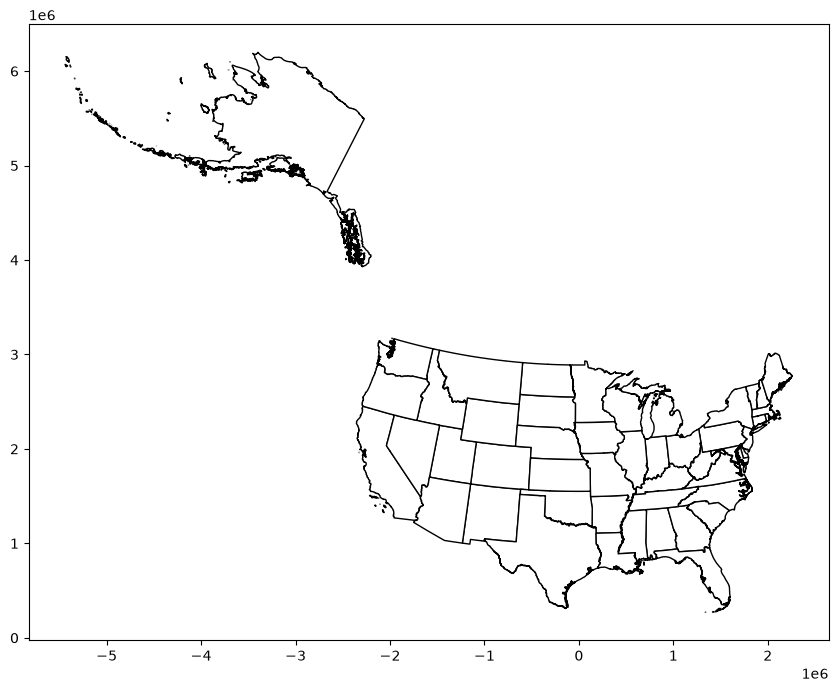

In [53]:
import geopandas as gpd
import matplotlib.pyplot as plt
import ssl
import certifi
import urllib.request
import io

census_url = "https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_state_500k.zip"
# url_state = "cb_2024_us_state_500k.zip"

context = ssl.create_default_context(cafile=certifi.where())

with urllib.request.urlopen(census_url, context=context) as response:
    state_zip = response.read()

states = gpd.read_file(io.BytesIO(state_zip))

#Remove Hawaii and territories
#Have to include Alaska because that is where a lot of grizzly bears are
contiguous_us = states.loc[
    ~states["STUSPS"].isin(["HI", "PR", "VI", "GU", "MP", "AS"])
].copy()

#Project the map
contiguous_us = contiguous_us.to_crs(epsg=5070)

#Plot
contiguous_us.plot(edgecolor="black", facecolor="white", figsize=(12, 8))
plt.show()

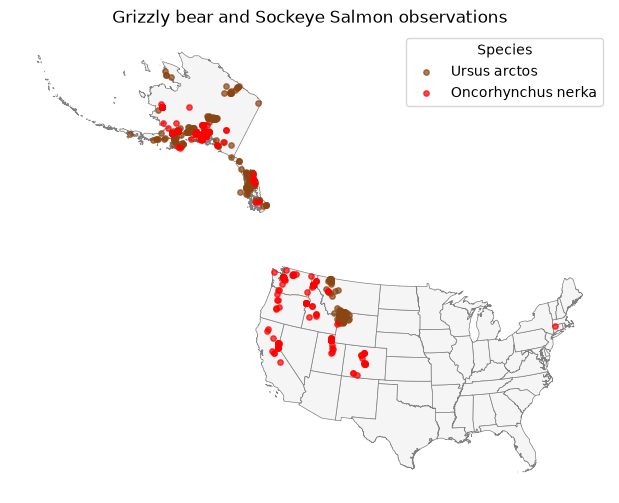

In [54]:
occurrence_points = gpd.GeoDataFrame(
    occurrences.copy(),
    geometry=gpd.points_from_xy( ## the method is calleed points_from_xy
        occurrences["decimalLongitude"], # x
        occurrences["decimalLatitude"] # y
        ),
    crs="EPSG:4326" # often the crs is in 4326 if it is a lat lon coordinate
    )

occurrence_points = occurrence_points.to_crs(epsg=5070)

fig, ax = plt.subplots(figsize=(12, 6))
contiguous_us.plot(
    ax=ax,
    facecolor="whitesmoke",
    edgecolor="gray",
    linewidth=0.5
)

colors = {"Ursus arctos": "saddlebrown", "Oncorhynchus nerka": "red"}

for species, color in colors.items():
    occurrence_points.loc[
        occurrence_points["queried_species"] == species
    ].plot(
        ax=ax,
        color=color,
        markersize=15,
        alpha=0.7,
        label=species
    )

ax.set_title("Grizzly bear and Sockeye Salmon observations")
ax.legend(title="Species")
ax.set_axis_off()

plt.show()

In [55]:
points_by_state = gpd.sjoin(
    occurrence_points,
    contiguous_us[["NAME", "STUSPS", "geometry"]],
    how="inner",
    predicate="within"
).drop(columns="index_right")

points_by_state.head()

,queried_species,decimalLongitude,decimalLatitude,geometry,NAME,STUSPS
0,Oncorhynchus nerka,-116.682100,47.627185,POINT (-1552852.319 2906665.909),Idaho,ID
1,Oncorhynchus nerka,-122.285270,44.752047,POINT (-2051032.781 2703591.284),Oregon,OR
2,Oncorhynchus nerka,-117.376375,46.635217,POINT (-1628585.046 2811240.372),Washington,WA
3,Oncorhynchus nerka,-122.096175,44.767914,POINT (-2036172.852 2701224.923),Oregon,OR
4,Oncorhynchus nerka,-161.091447,60.517558,POINT (-3683965.243 5418994.99),Alaska,AK


In [56]:
counts = (
    points_by_state
    .groupby(["NAME", "queried_species"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["Ursus arctos", "Oncorhynchus nerka"], fill_value=0)
)
counts.head()

queried_species,Ursus arctos,Oncorhynchus nerka
NAME,,
Alaska,360,143
California,0,25
Colorado,0,18
Connecticut,0,1
Idaho,1,31


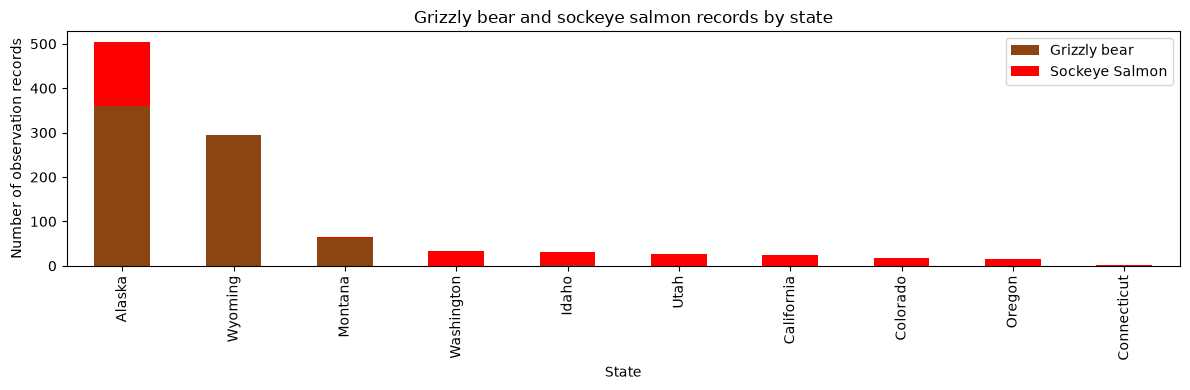

In [57]:
def barPlot(ax, counts):
    counts = counts.loc[
        counts.sum(axis=1).sort_values(ascending=False).index
    ]

    counts[["Ursus arctos", "Oncorhynchus nerka"]].plot.bar(
        ax=ax,
        stacked=True,
        color=["saddlebrown", "red"]
    )

    ax.set_xlabel("State")
    ax.set_ylabel("Number of observation records")
    ax.set_title("Grizzly bear and sockeye salmon records by state")
    ax.legend(["Grizzly bear", "Sockeye Salmon"])
    ax.tick_params(axis="x", labelrotation=90)

    return ax

fig, ax = plt.subplots(figsize=(12, 4)) 
ax = barPlot(ax,counts)
fig.tight_layout()
plt.show()

In [58]:
%pip install mapclassify

Note: you may need to restart the kernel to use updated packages.


In [59]:
import mapclassify

def choroplethMap(ax, contiguous_us, counts):
    # Total observations per state.
    totals = counts.sum(axis=1).rename("total")

    # Join totals to the state polygons.
    state_map = contiguous_us.merge(
        totals,
        left_on="NAME",
        right_index=True,
        how="left"
    )

    # States without records receive zero.
    state_map["total"] = state_map["total"].fillna(0)

    state_map.plot(
        column="total",
        cmap="RdPu", # This color was selected by me not Ai 
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"label": "Number of observation records"},
        ax=ax
    )

    ax.set_title("Grizzly bear and Sockeye Salmon observations by state")
    ax.set_axis_off()

    return ax

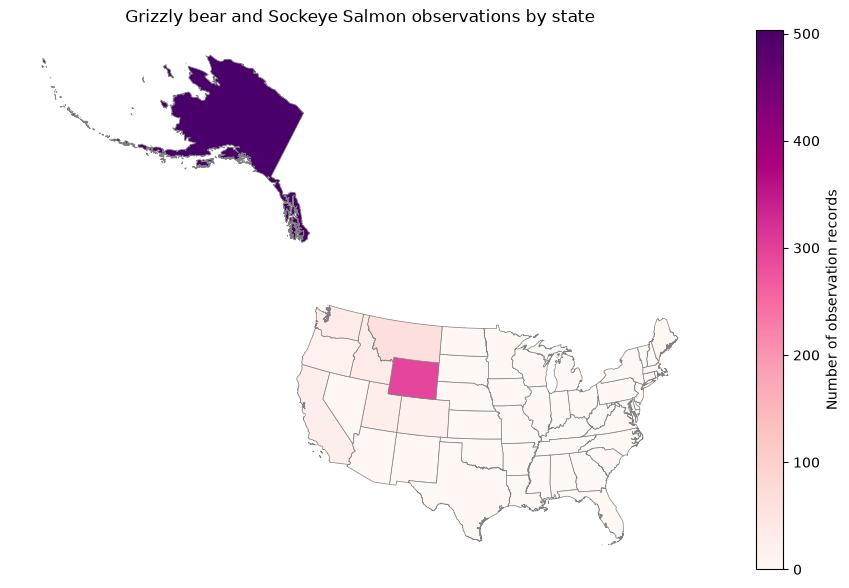

In [60]:
fig, ax = plt.subplots(figsize=(12, 7))

choroplethMap(ax, contiguous_us, counts)

plt.show()

In [71]:
def choroplethEqual(ax, contiguous_us, counts):
    totals = counts.sum(axis=1).rename("total")

    state_map = contiguous_us.merge(
        totals, left_on="NAME", right_index=True, how="left"
    )
    state_map["total"] = state_map["total"].fillna(0)

    state_map.plot(
        column="total",
        scheme="equalinterval",
        k=5,
        cmap="RdPu",
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"title": "Observation records", "fontsize": 8},
        ax=ax
    )

    ax.set_title("Equal interval")
    ax.set_axis_off()
    return ax

def choroplethQuantiles(ax, contiguous_us, counts):
    totals = counts.sum(axis=1).rename("total")

    state_map = contiguous_us.merge(
        totals, left_on="NAME", right_index=True, how="left"
    )
    state_map["total"] = state_map["total"].fillna(0)

    state_map.plot(
        column="total",
        scheme="quantiles",
        k=5,
        cmap="RdPu",
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"title": "Observation records", "fontsize": 8},
        ax=ax
    )

    ax.set_title("Quantiles")
    ax.set_axis_off()
    return ax

def choroplethNatural(ax, contiguous_us, counts):
    totals = counts.sum(axis=1).rename("total")

    state_map = contiguous_us.merge(
        totals, left_on="NAME", right_index=True, how="left"
    )
    state_map["total"] = state_map["total"].fillna(0)

    state_map.plot(
        column="total",
        scheme="fisherjenks",
        k=5,
        cmap="RdPu",
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"title": "Observation records", "fontsize": 8},
        ax=ax
    )

    ax.set_title("Natural breaks (Fisher–Jenks)")
    ax.set_axis_off()
    return ax

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/mapclassify/classifiers.py:1767: UserWarning: Not enough unique values in array to form 5 classes. Setting k to 3.
  self.bins = quantile(y, k=k)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/geopandas/plotting.py:746: UserWarning: Numba not installed. Using slow pure python version.
  binning = mapclassify.classify(


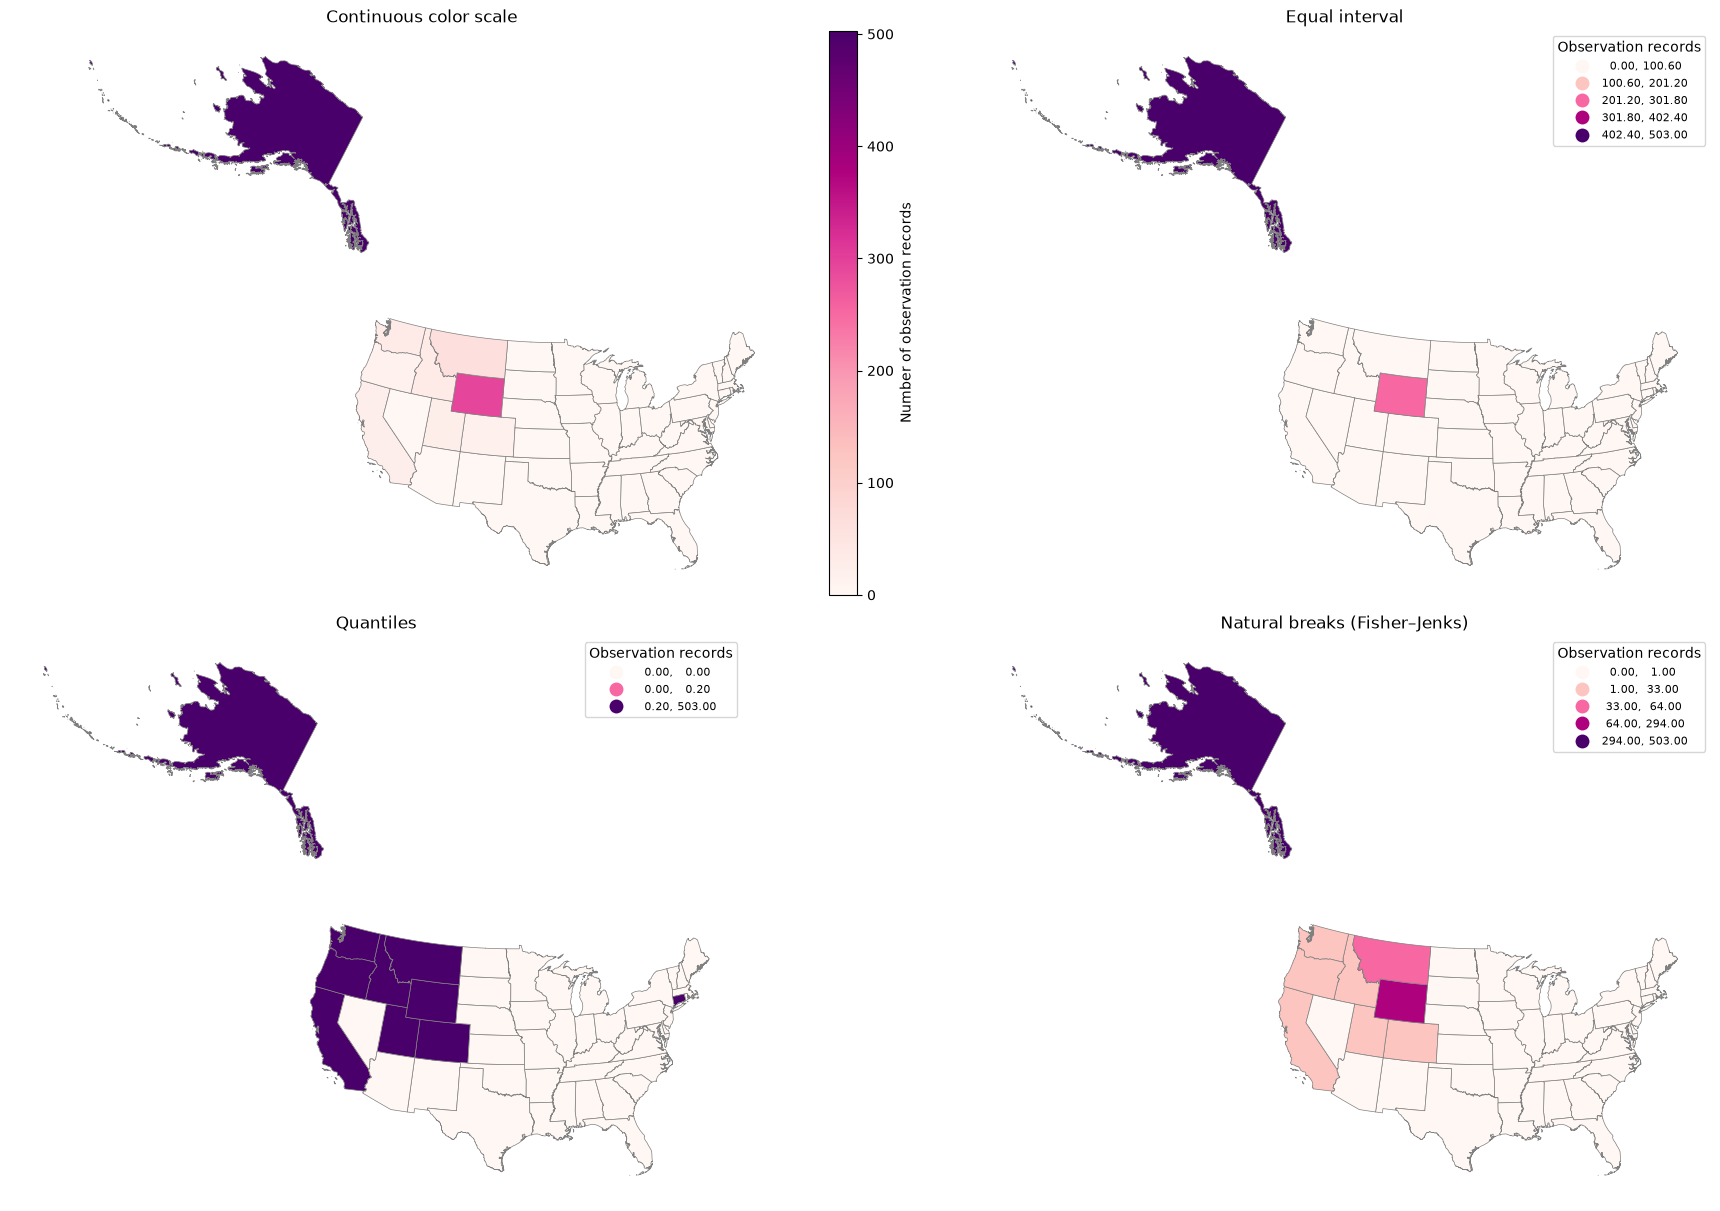

In [72]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 12),
    layout="constrained"
)

choroplethMap(axes[0, 0], contiguous_us, counts)
axes[0, 0].set_title("Continuous color scale")

choroplethEqual(axes[0, 1], contiguous_us, counts)
choroplethQuantiles(axes[1, 0], contiguous_us, counts)
choroplethNatural(axes[1, 1], contiguous_us, counts)

plt.show()

In [73]:
fig.savefig("grizzly_salmon_classification.png", dpi=300, bbox_inches="tight")
plt.show()

Oncorhynchus nerka positive-count median: 25.0
Ursus arctos positive-count median: 178.0


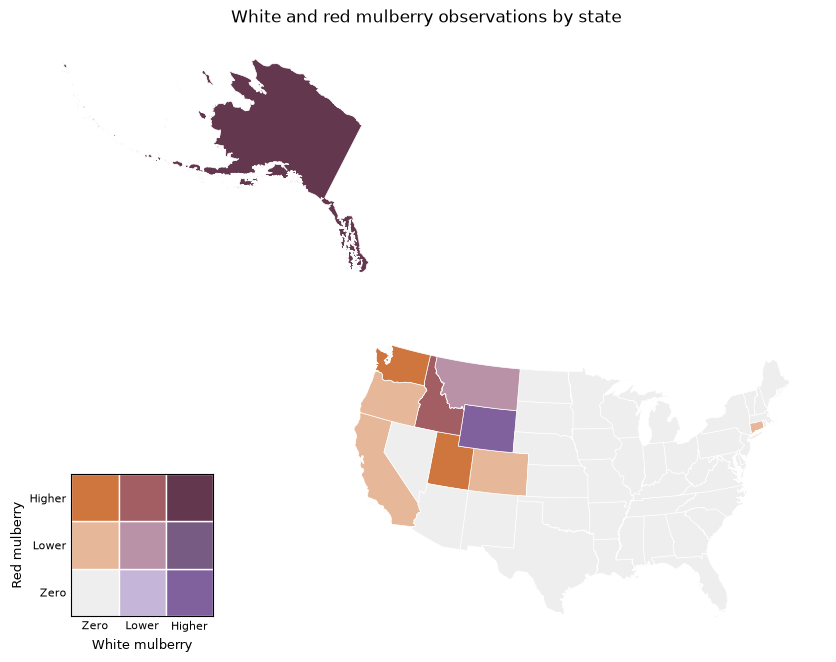

In [66]:
# Bivariate

import numpy as np
from matplotlib.patches import Rectangle

# Attach each species' counts to the state polygons.
bivariate = contiguous_us.merge(
    counts,
    left_on="NAME",
    right_index=True,
    how="left"
)

species = ["Oncorhynchus nerka", "Ursus arctos"]
bivariate[species] = bivariate[species].fillna(0)

# Classify each species:
# 0 = no records
# 1 = positive count at or below the positive-count median
# 2 = count above that median
for name in species:
    values = bivariate[name]
    median = values.loc[values > 0].median()

    bivariate[name + "_class"] = np.select(
        [values == 0, values <= median],
        [0, 1],
        default=2
    )

    print(name, "positive-count median:", median)

# Rows represent increasing red mulberry counts.
# Columns represent increasing white mulberry counts.
palette = np.array([
    ["#eeeeee", "#c5b5d8", "#80619e"],
    ["#e6b899", "#b992a8", "#785b82"],
    ["#cf763e", "#a35e63", "#63384f"]
])

bivariate["color"] = [
    palette[red, white]
    for red, white in zip(
        bivariate["Oncorhynchus nerka_class"],
        bivariate["Ursus arctos_class"]
    )
]

fig, ax = plt.subplots(figsize=(13, 8))

bivariate.plot(
    color=bivariate["color"],
    edgecolor="white",
    linewidth=0.5,
    ax=ax
)

ax.set_title("White and red mulberry observations by state")
ax.set_axis_off()

# Add a 3 × 3 bivariate legend.
legend_ax = ax.inset_axes([0.05, 0.05, 0.19, 0.23])

for red in range(3):
    for white in range(3):
        legend_ax.add_patch(
            Rectangle(
                (white, red), 1, 1,
                facecolor=palette[red, white],
                edgecolor="white"
            )
        )

legend_ax.set_xlim(0, 3)
legend_ax.set_ylim(0, 3)
legend_ax.set_aspect("equal")

legend_ax.set_xticks([0.5, 1.5, 2.5])
legend_ax.set_yticks([0.5, 1.5, 2.5])
legend_ax.set_xticklabels(["Zero", "Lower", "Higher"], fontsize=8)
legend_ax.set_yticklabels(["Zero", "Lower", "Higher"], fontsize=8)

legend_ax.set_xlabel("White mulberry", fontsize=9)
legend_ax.set_ylabel("Red mulberry", fontsize=9)
legend_ax.tick_params(length=0)

plt.show()

In [68]:
fig.savefig("grizzly_salmon_bivariate.png", dpi=300, bbox_inches="tight")
fig.savefig("grizzly_salmon_bivariate.pdf", bbox_inches="tight")
plt.show()

The 4 chloropleths show how classification changes the pattern in the combined number of records. Equal interval uses the same numerical ranges. Quantile classification distributes states relatively evenly among classes, showing the differences in relative ranking. Fisher-jenks (natural breaks) highlights natural groupings within the data. Comparing these classifications shows how different cartographic choices affect which states appear to have the greatest concentration of observations.

The bivariate map compares each states independently. States with higher record classes for both species need to be investigated further, but this does not demonstrate a predator-prey relationship. I think I want to explore finer-scale map of records in Alaska.